# 03 · Variance metrics and analysis
**Project:** Sales Variance FP&A Dashboard

The analysis is done by `scripts/sales_variance_analysis.py`. It writes `data/processed/Sales_Variance_Enriched_Data.csv` and the workbook `outputs/Sales_Variance_Analysis.xlsx`.
This notebook **re-computes the key numbers independently** with plain pandas and checks they agree with the workbook.

Definitions (all amounts in USD, percentages are `sum(variance) / sum(target)`, never an average of row percentages):

| Effect | Formula (per line) |
|---|---|
| Volume | (Actual_Qty − Target_Qty) × Target_Price |
| Price | Actual_Qty × (Actual_Price − Target_Price) |
| Cost (gross profit only) | −Actual_Qty × (Actual_Cost − Target_Cost) |

At group level the volume effect is split into **pure volume** (total units × average target price) and **mix** (selling a different combination than planned).

In [1]:
import sys
from pathlib import Path

import pandas as pd

# Works whether Jupyter starts in notebooks/ or in the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from fpa_lib import config  # noqa: E402

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
pd.options.display.max_colwidth = 90
rel = lambda p: p.relative_to(ROOT).as_posix()  # noqa: E731  (print paths without your local folder names)
import matplotlib.pyplot as plt  # noqa: E402

df = pd.read_csv(config.ENRICHED_CSV, dtype={"Line_ID": str, "Notes": str}, keep_default_na=False, na_values=[""])
wb = pd.read_excel(config.ANALYSIS_XLSX, sheet_name=None)
cents = lambda s: (s * 100).round().astype("int64")  # noqa: E731  (exact sums in cents)
print(f"Lines: {len(df):,}   months: {df['Year_Month'].nunique()}   workbook sheets: {len(wb)}")

Lines: 20,900   months: 24   workbook sheets: 20


## 1. Headline numbers

In [2]:
ts, as_ = cents(df["Target_Sales_USD"]).sum(), cents(df["Actual_Sales_USD"]).sum()
tg, ag = cents(df["Target_Gross_Profit_USD"]).sum(), cents(df["Actual_Gross_Profit_USD"]).sum()
vol = ((df["Actual_Qty"] - df["Target_Qty"]) * cents(df["Target_Unit_Price_USD"])).sum()
price = (df["Actual_Qty"] * (cents(df["Actual_Unit_Price_USD"]) - cents(df["Target_Unit_Price_USD"]))).sum()
cost = -(df["Actual_Qty"] * (cents(df["Actual_Unit_Cost_USD"]) - cents(df["Target_Unit_Cost_USD"]))).sum()
head = pd.Series({
    "Target sales": ts / 100, "Actual sales": as_ / 100, "Sales variance": (as_ - ts) / 100,
    "Sales variance %": (as_ - ts) / ts * 100, "Volume effect (incl. mix)": vol / 100, "Price effect": price / 100,
    "Gross-profit variance": (ag - tg) / 100, "Gross-profit variance %": (ag - tg) / tg * 100,
    "Cost effect on gross profit": cost / 100,
    "Target gross margin %": tg / ts * 100, "Actual gross margin %": ag / as_ * 100,
})
assert vol + price == as_ - ts, "revenue bridge does not add up"
head.to_frame("value")

,value
Target sales,"533,083,643.29"
Actual sales,"522,191,080.53"
Sales variance,"-10,892,562.76"
Sales variance %,-2.04
Volume effect (incl. mix),"269,703.87"
Price effect,"-11,162,266.63"
Gross-profit variance,"-13,283,618.09"
Gross-profit variance %,-6.53
Cost effect on gross profit,"-2,142,168.53"
Target gross margin %,38.18


## 2. Agreement with the workbook

In [3]:
company = wb["Company"].iloc[0]
checks = {
    "Sales variance": (company["Sales_Variance_USD"], (as_ - ts) / 100),
    "Gross-profit variance": (company["Gross_Profit_Variance_USD"], (ag - tg) / 100),
    "Price effect": (company["Price_Effect_USD"], price / 100),
    "Pure volume + mix": (company["Volume_Pure_USD"] + company["Mix_Effect_USD"], vol / 100),
    "Cost effect": (company["Profit_Cost_Effect_USD"], cost / 100),
}
out = pd.DataFrame(checks, index=["workbook", "pandas"]).T
out["difference"] = (out["workbook"] - out["pandas"]).abs()
assert (out["difference"] < 0.005).all(), "pandas and the workbook disagree"
out

,workbook,pandas,difference
Sales variance,"-10,892,562.76","-10,892,562.76",0.00
Gross-profit variance,"-13,283,618.09","-13,283,618.09",0.00
Price effect,"-11,162,266.63","-11,162,266.63",0.00
Pure volume + mix,"269,703.87","269,703.87",0.00
Cost effect,"-2,142,168.53","-2,142,168.53",0.00


## 3. Revenue bridge: target to actual

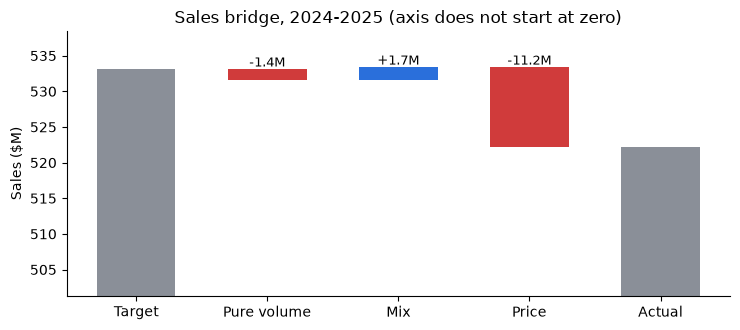

In [4]:
steps = [("Target", ts / 100), ("Pure volume", company["Volume_Pure_USD"]), ("Mix", company["Mix_Effect_USD"]),
         ("Price", company["Price_Effect_USD"])]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
level = steps[0][1]
ax.bar(0, level / 1e6, color="#8a8f98", width=0.6)
for i, (name, v) in enumerate(steps[1:], start=1):
    ax.bar(i, v / 1e6, bottom=level / 1e6, color="#2a6fdb" if v >= 0 else "#d03b3b", width=0.6)
    ax.text(i, (level + max(v, 0)) / 1e6 + 0.4, f"{v / 1e6:+,.1f}M", ha="center", fontsize=9)
    level += v
ax.bar(len(steps), level / 1e6, color="#8a8f98", width=0.6)
ax.set_xticks(range(len(steps) + 1), [s[0] for s in steps] + ["Actual"])
ax.set_ylim(min(ts, as_) / 100 / 1e6 * 0.96, max(ts, as_) / 100 / 1e6 * 1.01)
ax.set_ylabel("Sales ($M)")
ax.set_title("Sales bridge, 2024-2025 (axis does not start at zero)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 4. By region (recomputed vs workbook)

In [5]:
g = df.assign(TS=cents(df["Target_Sales_USD"]), AS=cents(df["Actual_Sales_USD"]),
             TG=cents(df["Target_Gross_Profit_USD"]), AG=cents(df["Actual_Gross_Profit_USD"])).groupby("Region")[
    ["TS", "AS", "TG", "AG"]].sum()
region = pd.DataFrame({"Sales_Var_USD": (g.AS - g.TS) / 100, "Sales_Var_Pct": (g.AS - g.TS) / g.TS * 100,
                       "GP_Var_Pct": (g.AG - g.TG) / g.TG * 100}).sort_values("Sales_Var_Pct")
wb_region = wb["By_Region"].set_index("Region")
diff = (region["Sales_Var_USD"] - wb_region["Sales_Variance_USD"]).abs().max()
print(f"Largest difference vs the workbook: ${diff:,.4f}")
assert diff < 0.005
region.join(wb_region[["Price_Effect_USD", "Mix_Effect_USD", "Sales_Variance_Status"]])

Largest difference vs the workbook: $0.0000


,Sales_Var_USD,Sales_Var_Pct,GP_Var_Pct,Price_Effect_USD,Mix_Effect_USD,Sales_Variance_Status
Region,,,,,,
Latin America,"-7,013,243.81",-10.65,-17.01,"-1,247,520.10","304,784.42",Unfavorable
Europe,"-5,915,055.96",-5.10,-10.46,"-3,108,889.72","-127,266.78",Unfavorable
North America,"-4,343,395.79",-2.90,-7.16,"-3,197,092.85","1,074,628.81",Within tolerance
Middle East,"969,889.34",1.36,-3.02,"-1,430,236.22","11,370.68",Within tolerance
Asia Pacific,"5,409,243.46",4.15,0.19,"-2,178,527.74","-295,118.62",Favorable


## 5. Monthly variance

Months below target: 20 of 24


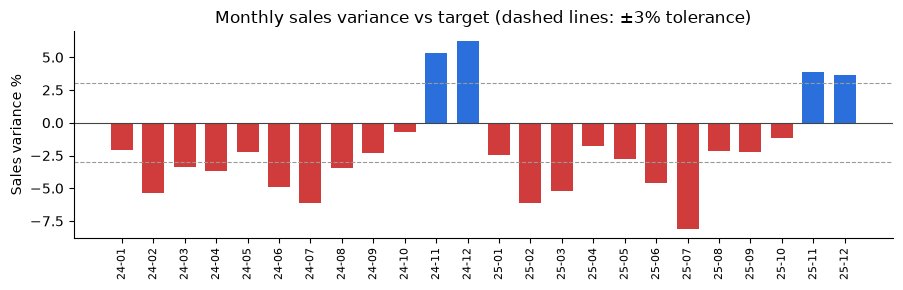

In [6]:
monthly = wb["By_Year_Month"].set_index("Year_Month")
below = (monthly["Sales_Variance_USD"] < 0).sum()
print(f"Months below target: {below} of {len(monthly)}")
fig, ax = plt.subplots(figsize=(9, 3))
v = monthly["Sales_Variance_Pct"]
ax.bar(range(len(v)), v, color=["#d03b3b" if x < 0 else "#2a6fdb" for x in v], width=0.7)
ax.axhline(0, color="#444", lw=0.8)
for y in (3, -3):
    ax.axhline(y, color="#999", lw=0.8, ls="--")
ax.set_xticks(range(len(v)), [str(i)[2:] for i in v.index], rotation=90, fontsize=8)
ax.set_ylabel("Sales variance %")
ax.set_title("Monthly sales variance vs target (dashed lines: ±3% tolerance)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Discounts: volume vs profit

In [7]:
wb["By_Price_Band"][["Price_Band", "Lines", "Qty_Attainment_Pct", "Sales_Variance_Pct", "Gross_Profit_Variance_Pct",
                      "Price_Realisation_Pct"]]

,Price_Band,Lines,Qty_Attainment_Pct,Sales_Variance_Pct,Gross_Profit_Variance_Pct,Price_Realisation_Pct
0,1. Discount of 5% or more,4063,112.11,3.39,-16.04,-9.03
1,2. Discount of 1-5%,1956,95.39,-6.51,-11.14,-1.80
2,3. At target price (within 1%),13259,96.49,-3.52,-3.97,0.03
3,4. Above target price (over 1%),1622,100.86,0.95,2.29,1.39


## 7. How good were the targets? (2025)
WAPE = sum of |actual − target| / sum of actual, by region and month. The naive benchmark is "same month last year". A target worse than the naive benchmark is a planning problem, not only a sales problem.

In [8]:
wb["Target_Accuracy"]

,Region,Months,Actual_Sales_2025_USD,Target_WAPE_Pct,Naive_WAPE_Pct,Target_Bias_Pct,Naive_Bias_Pct,Months_Target_Closer,More_Accurate
0,Asia Pacific,12,"72,178,098.83",6.07,11.81,-5.99,-11.81,10,Target
1,Europe,12,"55,232,002.67",8.01,2.55,8.01,-0.88,1,Naive forecast
2,Latin America,12,"29,149,404.38",16.48,3.70,16.48,1.78,0,Naive forecast
3,Middle East,12,"36,942,284.88",3.51,5.45,-2.09,-4.65,8,Target
4,North America,12,"75,252,458.85",4.13,6.79,2.97,-6.79,8,Target
5,Company,12,"268,754,249.61",3.74,5.70,2.37,-5.70,10,Target


## 8. Validation summary

In [9]:
v = wb["Validation_Summary"]
print(f"Checks: {(v['Status'] == 'PASS').sum()} of {len(v)} pass")
v[v["Status"] != "PASS"]

Checks: 41 of 41 pass


,Status,Check,Detail


## Next
* Interactive dashboard: `dashboard/Sales_Variance_Dashboard.html` (open it in any browser, works offline).
* Findings and recommendations: `docs/Insights_and_Recommendations.md`.